# When is the gym empty?

Relative occupancy (0 = empty, 1 = full) crawled from the MyGym API, aggregated by weekday and 30-minute slot in Europe/Berlin local time. Berlin public holidays are excluded.

Re-executed weekly by a GitHub Action; outputs are saved so GitHub renders them directly.

In [1]:
from pathlib import Path

import holidays
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Only the most recent months are used, to limit the effect of drift.
WINDOW_MONTHS = 12
SLOT = "30min"
TIMEZONE = "Europe/Berlin"
WEEKDAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

DATA_DIR = Path("..")
sns.set_theme(style="white")

In [2]:
files = sorted(DATA_DIR.glob("20[0-9][0-9]/20[0-9][0-9]-[0-9][0-9].csv"))
raw = pd.concat(
    (pd.read_csv(f, header=None, names=["timestamp", "occupancy"]) for f in files),
    ignore_index=True,
)
raw["timestamp"] = pd.to_datetime(raw["timestamp"], utc=True, format="ISO8601")
raw = raw.drop_duplicates("timestamp").sort_values("timestamp")

# Naive local time so that DST shifts keep slots aligned to the wall clock.
raw["local"] = raw["timestamp"].dt.tz_convert(TIMEZONE).dt.tz_localize(None)
print(f"{len(raw):,} samples from {raw['local'].min():%Y-%m-%d} to {raw['local'].max():%Y-%m-%d}")

174,615 samples from 2022-05-18 to 2026-11-05


In [3]:
cutoff = raw["local"].max() - pd.DateOffset(months=WINDOW_MONTHS)
df = raw[raw["local"] >= cutoff].copy()

public_holidays = holidays.Germany(subdiv="BE", years=sorted(df["local"].dt.year.unique()))
is_holiday = df["local"].dt.date.isin(public_holidays.keys())
df = df[~is_holiday]

df["weekday"] = df["local"].dt.day_of_week
df["slot"] = df["local"].dt.floor(SLOT).dt.strftime("%H:%M")
print(f"{len(df):,} samples in window, {is_holiday.sum():,} holiday samples excluded")

12,187 samples in window, 411 holiday samples excluded


## Median occupancy by weekday and time of day

Darker is busier. Slots without any sample stay blank.

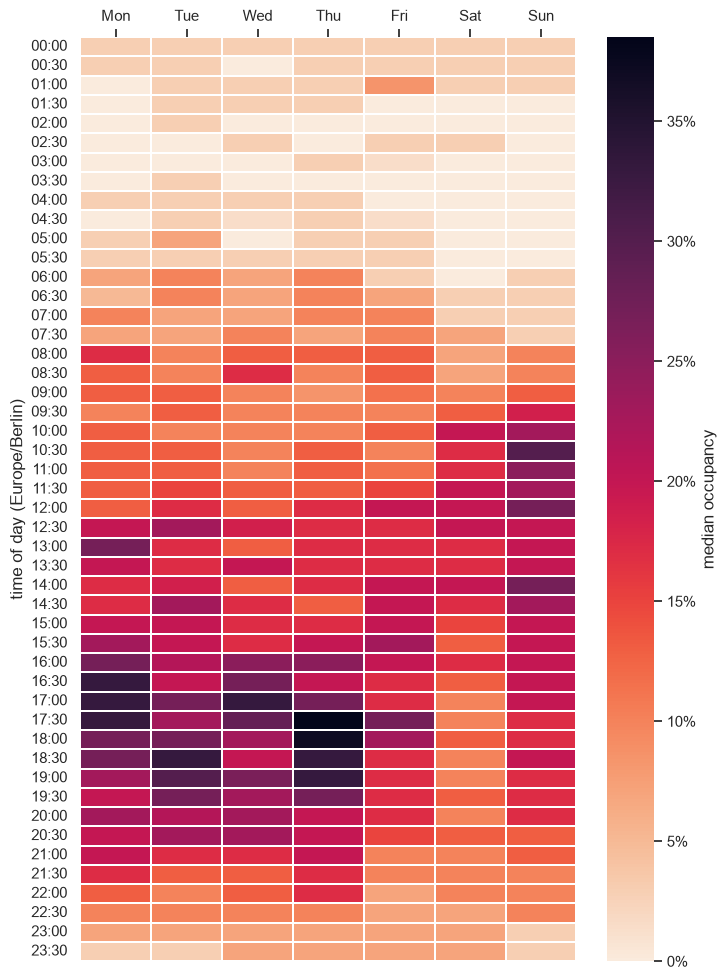

In [4]:
heatmap = df.pivot_table(index="slot", columns="weekday", values="occupancy", aggfunc="median")
heatmap = heatmap.reindex(columns=range(7))
heatmap.columns = WEEKDAYS

fig, ax = plt.subplots(figsize=(8, 12))
sns.heatmap(
    heatmap,
    cmap="rocket_r",
    vmin=0,
    linewidths=0.2,
    cbar_kws={"label": "median occupancy", "format": "{x:.0%}"},
    ax=ax,
)
ax.set(xlabel="", ylabel="time of day (Europe/Berlin)")
ax.xaxis.tick_top()
plt.show()

## Spread per weekday

Median with the 25th to 75th percentile band.

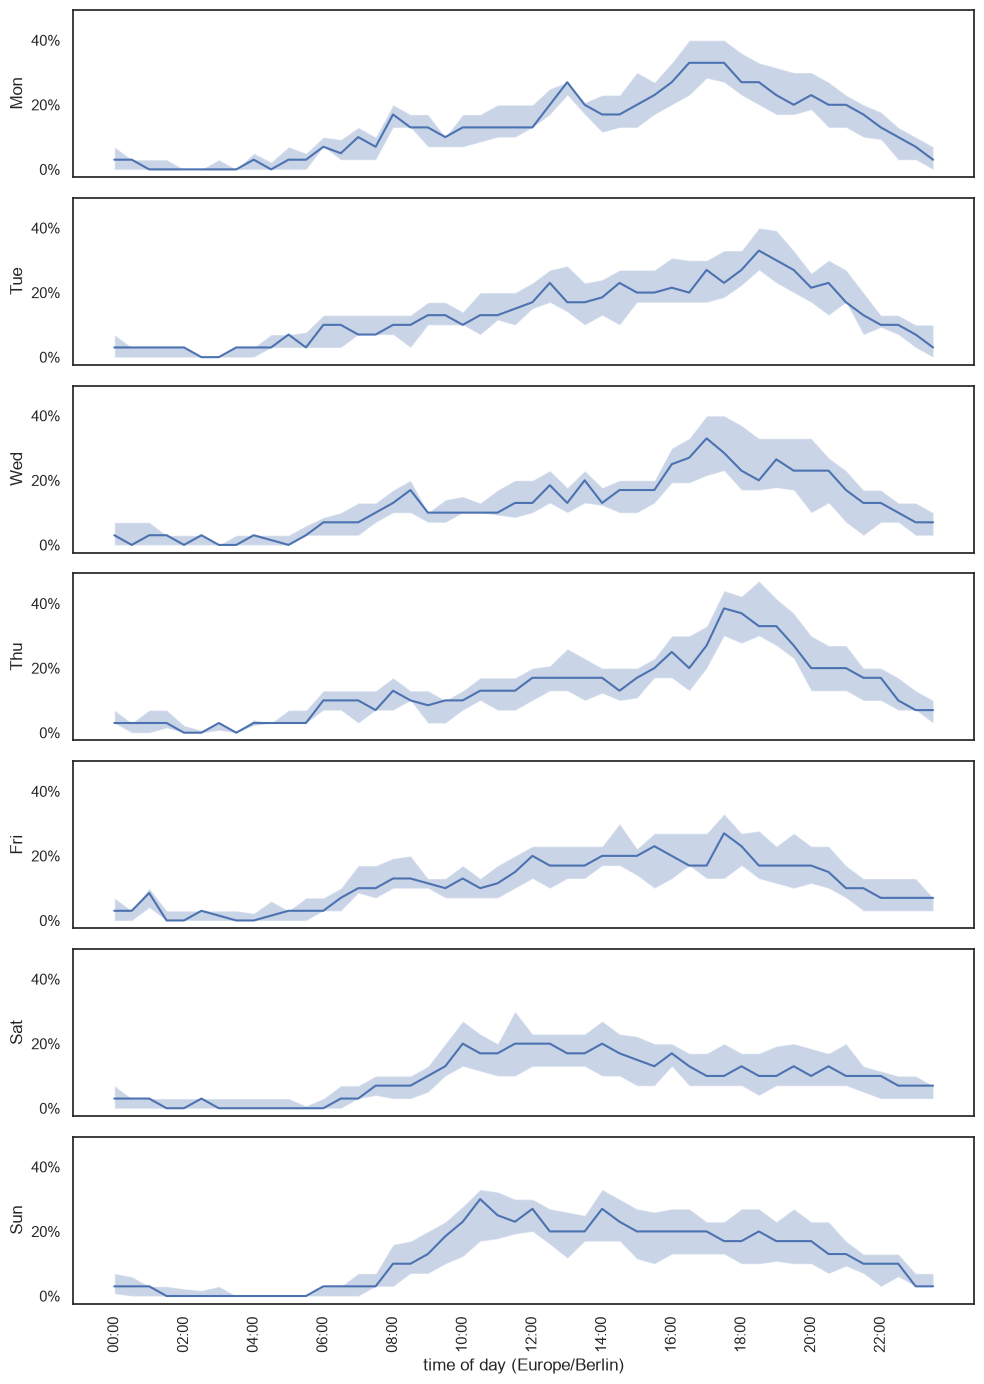

In [5]:
stats = (
    df.groupby(["weekday", "slot"])["occupancy"]
    .quantile([0.25, 0.5, 0.75])
    .unstack()
    .rename(columns={0.25: "p25", 0.5: "median", 0.75: "p75"})
)
slots = sorted(df["slot"].unique())

fig, axes = plt.subplots(7, 1, figsize=(10, 14), sharex=True, sharey=True)
for day, ax in enumerate(axes):
    if day not in stats.index.get_level_values("weekday"):
        continue
    day_stats = stats.loc[day].reindex(slots)
    x = range(len(slots))
    ax.fill_between(x, day_stats["p25"], day_stats["p75"], alpha=0.3)
    ax.plot(x, day_stats["median"])
    ax.set_ylabel(WEEKDAYS[day])
    ax.yaxis.set_major_formatter("{x:.0%}")

axes[-1].set_xticks(range(0, len(slots), 4), slots[::4], rotation=90)
axes[-1].set_xlabel("time of day (Europe/Berlin)")
fig.tight_layout()
plt.show()

## Quietest slot by time of day

For each weekday, the slot within each window with the lowest median occupancy.

In [6]:
WINDOWS = {
    "Morning": ("08:00", "10:30"),
    "Noon": ("12:00", "14:00"),
    "Evening": ("17:00", "20:30"),
}

best_slots = pd.concat(
    {
        name: pd.DataFrame(
            {
                "best slot": heatmap.loc[start:end].idxmin(),
                "median occupancy": heatmap.loc[start:end].min().map("{:.0%}".format),
            }
        )
        for name, (start, end) in WINDOWS.items()
    },
    axis=1,
)
best_slots.index.name = "weekday"
best_slots

Morning                       Noon                    Evening  \
        best slot median occupancy best slot median occupancy best slot   
weekday                                                                   
Mon         09:30              10%     12:00              13%     19:30   
Tue         08:00              10%     12:00              17%     20:00   
Wed         09:00              10%     12:00              13%     18:30   
Thu         09:00               8%     12:00              17%     20:00   
Fri         09:30              10%     12:30              17%     20:30   
Sat         08:00               7%     13:00              17%     17:00   
Sun         08:00              10%     12:30              20%     20:30   

                          
        median occupancy  
weekday                   
Mon                  20%  
Tue                  22%  
Wed                  20%  
Thu                  20%  
Fri                  15%  
Sat                  10%  
Sun                  13%

## Data quality

Samples per slot show how reliable each cell above is; gaps show where the crawler missed data.

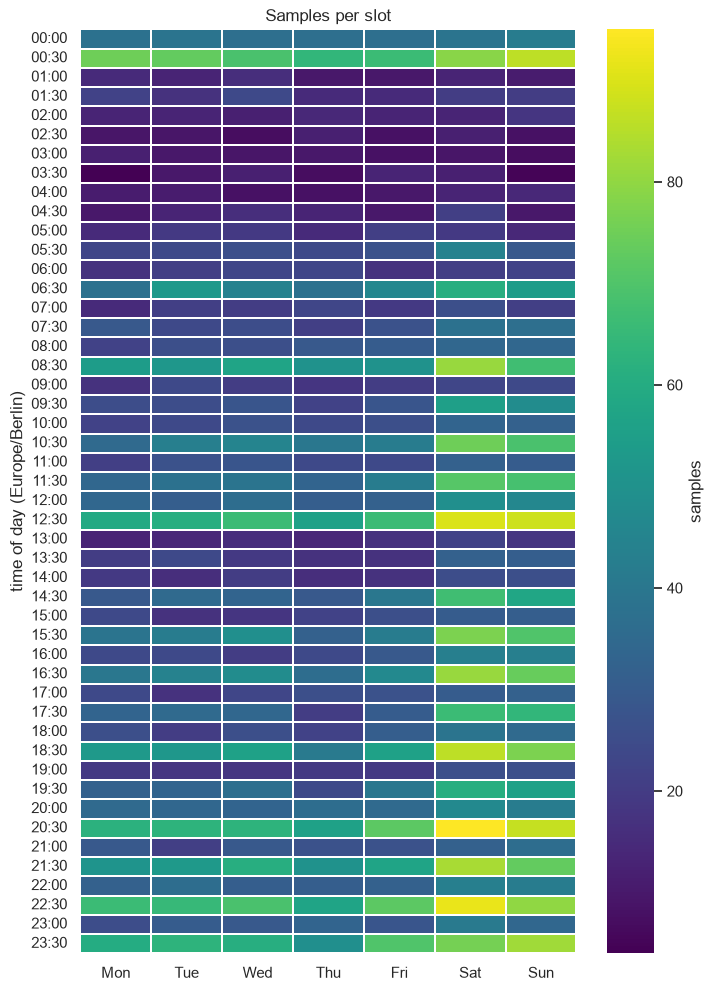

Median sampling interval: 0 days 00:06:46
Slot/weekday cells without samples: 0


,from,to,gap
174451,2026-10-05 12:42:08+00:00,2026-10-06 01:29:31+00:00,0 days 12:47:23
174202,2026-08-28 00:29:34+00:00,2026-08-28 11:39:28+00:00,0 days 11:09:54
174200,2026-08-27 04:37:58+00:00,2026-08-27 15:27:56+00:00,0 days 10:49:58
174604,2026-11-02 08:09:16+00:00,2026-11-02 18:13:33+00:00,0 days 10:04:17
174203,2026-08-28 11:39:28+00:00,2026-08-28 21:30:15+00:00,0 days 09:50:47
174481,2026-10-12 06:32:34+00:00,2026-10-12 15:58:32+00:00,0 days 09:25:58
173390,2026-08-06 15:16:29+00:00,2026-08-07 00:20:02+00:00,0 days 09:03:33
174201,2026-08-27 15:27:56+00:00,2026-08-28 00:29:34+00:00,0 days 09:01:38
174611,2026-11-04 07:29:58+00:00,2026-11-04 15:40:08+00:00,0 days 08:10:10
174607,2026-11-03 07:27:26+00:00,2026-11-03 15:22:56+00:00,0 days 07:55:30


In [7]:
counts = df.pivot_table(index="slot", columns="weekday", values="occupancy", aggfunc="count")
counts = counts.reindex(columns=range(7))
counts.columns = WEEKDAYS

fig, ax = plt.subplots(figsize=(8, 12))
sns.heatmap(counts, cmap="viridis", linewidths=0.2, cbar_kws={"label": "samples"}, ax=ax)
ax.set(xlabel="", ylabel="time of day (Europe/Berlin)", title="Samples per slot")
plt.show()

gaps = raw["timestamp"].diff()
long_gaps = (
    pd.DataFrame({"from": raw["timestamp"].shift(), "to": raw["timestamp"], "gap": gaps})
    .loc[gaps > pd.Timedelta(hours=6)]
    .sort_values("gap", ascending=False)
    .head(10)
)
print(f"Median sampling interval: {gaps.median()}")
print(f"Slot/weekday cells without samples: {int(counts.isna().sum().sum())}")
long_gaps